# To Gossip or Not To Gossip: The Evolution of Cooperation Under Horizontal Gene Transfer

**Authors:** Ananya, Shrayansh, Yogesh  
**Affiliation:** Behavior, Evolution, Emergence 2026 (BEE 2026), The Institute of Mathematical Sciences (IMSc), Chennai  
**Date:** June 20, 2026  
**Repository:** [The-Evolution-of-Cooperation-Under-Horizontal-Gene-Transfer](https://github.com/tshrayansh/The-Evolution-of-Cooperation-Under-Horizontal-Gene-Transfer)

---

## Executive Summary & Biological Context

Horizontal Gene Transfer (HGT) is the lateral transfer of genetic material between unicellular organisms without reproduction. Despite its high biological cost:
1. **Donor Burden:** Donors synthesize extensive conjugation machinery (type IV secretion pilus, relaxosome complex, ATP consumption).
2. **Altruistic Sharing:** Donors transfer advantageous genetic material to potential competitors.

Yet, over **80% of bacterial genomes** across history have been acquired through HGT. Why is HGT so pervasive when individual selection strongly penalizes costly gene donation?

This project systematically reconstructs the mathematical framework presented at **BEE 2026 (IMSc)** to explore the evolutionary dynamics of HGT in the context of a **bacterial public goods game** (e.g., siderophore secretion). We formulate, simulate, and analyze four progressive mathematical models:

1. **Base Model:** Standard replicator-conjugation dynamics with costs of cooperation ($f_c$) and HGT ($f_s$).
2. **Independent Beneficial Plasmid Model:** Universal fitness gain ($f_+$) carried on a mobile plasmid across 8 bacterial phenotypes.
3. **Dependent Beneficial Plasmid Model:** Conditional fitness gain ($f_+$) tied specifically to the cooperative phenotype across 6 bacterial phenotypes.
4. **Plasmid-Chromosome Synergy Model:** Direct positive epistasis ($f_{pc}$) between chromosomal HGT machinery and the cooperative plasmid.

---


In [1]:
import numpy as np
import scipy.integrate as spi
import matplotlib.pyplot as plt

# Matplotlib configuration for publication-ready figures
plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 14,
    "axes.titlesize": 15,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "figure.titlesize": 16,
    "figure.dpi": 150,
    "lines.linewidth": 2.2,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--"
})

# Consistent color palette matching BEE26 presentation
COLOR_GC = "#1f77b4"      # Generous Cooperator (Blue)
COLOR_GD = "#ff7f0e"      # Generous Defector (Orange)
COLOR_SC = "#2ca02c"      # Secretive Cooperator (Green)
COLOR_SD = "#d62728"      # Secretive Defector (Red)
COLOR_SC_PLUS = "#9467bd" # Secretive Cooperator with Plasmid (Purple)
COLOR_SD_PLUS = "#8c564b" # Secretive Defector with Plasmid (Brown)

print("Packages loaded successfully.")


Packages loaded successfully.


---
## 1. Model 1: The Base Model (Slides 7–10)

### 1.1 Strategy Space & Normalization
The bacterial population is partitioned across two binary traits:
- **HGT Strategy:** Generous ($G$, performs HGT) vs. Secretive ($S$, does not perform HGT).
- **Social Strategy:** Cooperator ($C$, produces public goods at cost $f_c$) vs. Defector ($D$, exploits public goods).

This yields four strategies with population fractions:
$$x = [GC, GD, SC, SD]^	op, \quad \sum_{i} x_i = GC + GD + SC + SD = 1$$

### 1.2 Fitness Definitions
Let the baseline fitness be $1$.
- $GC$ pays both the cooperation cost $f_c$ and the HGT cost $f_s$:
  $$f_{GC} = 1 - f_c$$
- $GD$ avoids the cooperation cost but performs HGT:
  $$f_{GD} = 1$$
- $SC$ pays the cooperation cost but avoids the HGT cost (earning the relative advantage $f_s$):
  $$f_{SC} = 1 + f_s - f_c$$
- $SD$ pays neither cost, reaping the HGT savings without cooperative investment:
  $$f_{SD} = 1 + f_s$$

### 1.3 Mean Population Fitness
The mean fitness $ar{f} = \sum_{i} x_i f_i$:
$$egin{aligned}
ar{f} &= GC(1 - f_c) + GD(1) + SC(1 + f_s - f_c) + SD(1 + f_s) \\
&= (GC + GD + SC + SD) - f_c(GC + SC) + f_s(SC + SD) \\
&= 1 - f_c(GC + SC) + f_s(SC + SD)
\end{aligned}$$

### 1.4 Conjugation Kinetics & Replicator Dynamics
Conjugation is donor-driven by generous cooperators ($GC$):
1. $GC + SD \xrightarrow{\alpha} GC + SC$ (Rate: $\alpha \cdot GC \cdot SD$)
2. $GC + GD \xrightarrow{\alpha} 2GC$ (Rate: $\alpha \cdot GC \cdot GD$)

The combined replicator-conjugation differential equations:
$$\begin{aligned}
\dot{GC} &= (f_{GC} - \bar{f})GC + \alpha \cdot GC \cdot GD \\
\dot{GD} &= (f_{GD} - \bar{f})GD - \alpha \cdot GC \cdot GD \\
\dot{SC} &= (f_{SC} - \bar{f})SC + \alpha \cdot GC \cdot SD \\
\dot{SD} &= (f_{SD} - \bar{f})SD - \alpha \cdot GC \cdot SD
\end{aligned}$$

**Simplex Conservation Invariance:**
$$\sum_{i} \dot{x}_i = \sum_i (f_i - \bar{f})x_i + (\alpha GC GD - \alpha GC GD) + (\alpha GC SD - \alpha GC SD) = (\bar{f} - \bar{f}) + 0 = 0$$
Hence, the total population density is strictly conserved for all $t \ge 0$.


<>:43: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
<>:43: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
/var/folders/0t/5tbxwry574d123j3d6wxhrsh0000gn/T/ipykernel_64049/3171409283.py:43: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
  ax1.set_title("Base Model: Population Trajectory ($t \in [0, 100]$)", fontweight="bold")


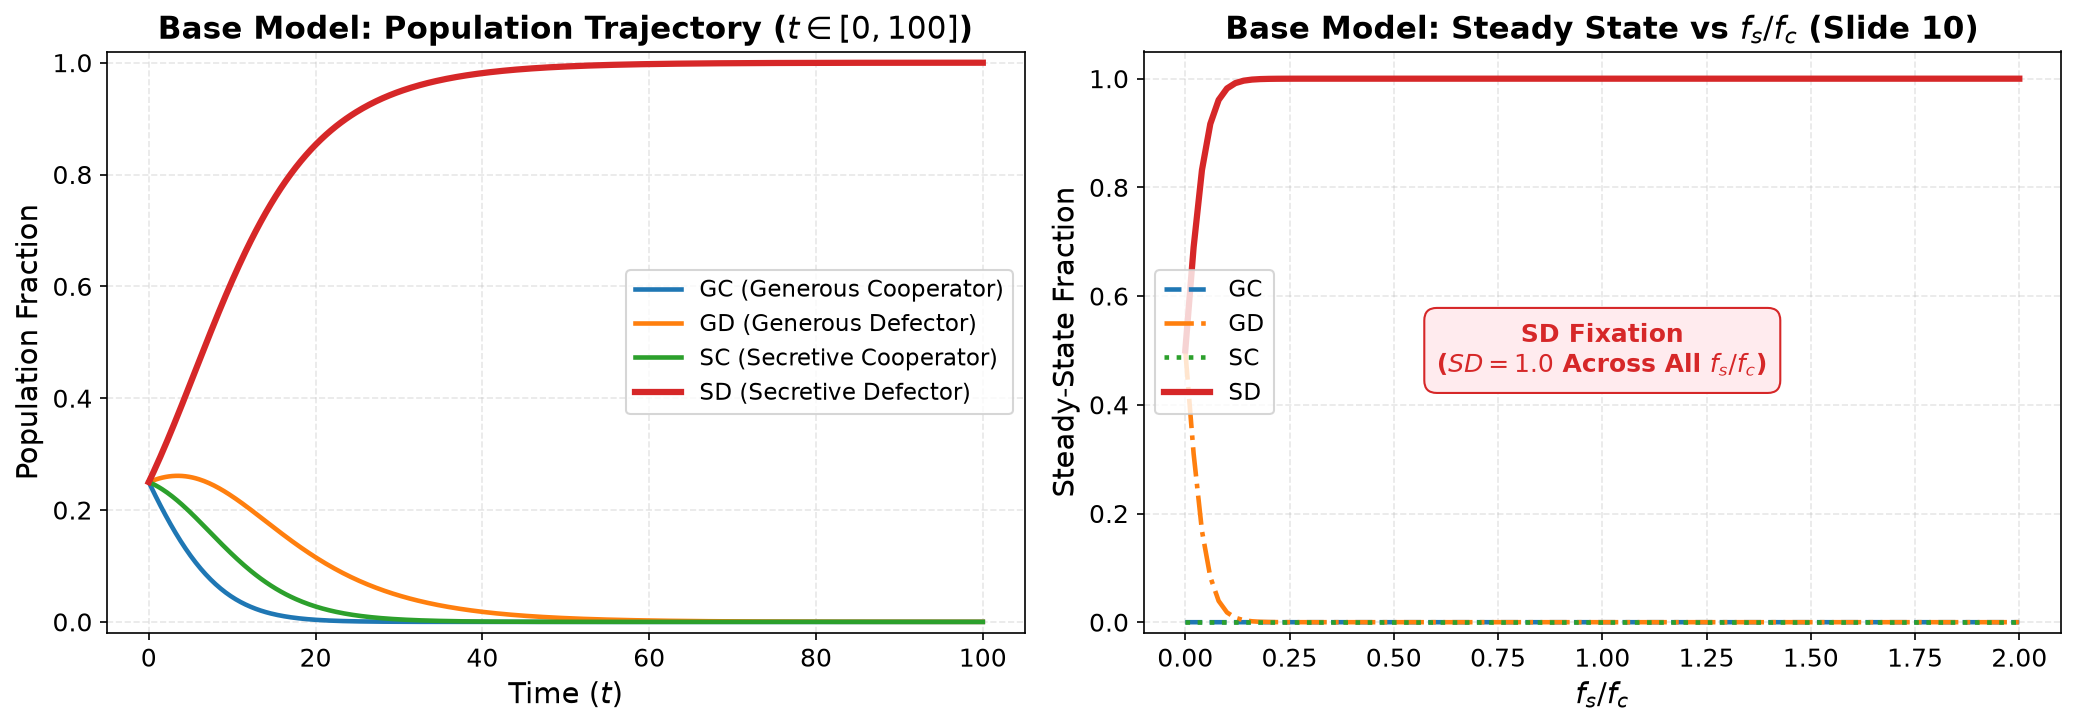

In [2]:
def base_model_ode(t, y, alpha, fc, fs):
    GC, GD, SC, SD = y
    f_GC = 1.0 - fc
    f_GD = 1.0
    f_SC = 1.0 + fs - fc
    f_SD = 1.0 + fs
    
    f_bar = 1.0 - fc * (GC + SC) + fs * (SC + SD)
    
    dGC = (f_GC - f_bar) * GC + alpha * GC * GD
    dGD = (f_GD - f_bar) * GD - alpha * GC * GD
    dSC = (f_SC - f_bar) * SC + alpha * GC * SD
    dSD = (f_SD - f_bar) * SD - alpha * GC * SD
    return [dGC, dGD, dSC, dSD]

# 1. Simulate time series
t_span = (0, 100)
t_eval = np.linspace(0, 100, 500)
y0 = [0.25, 0.25, 0.25, 0.25]
alpha = 0.1
fc = 0.2
fs = 0.1

sol_base = spi.solve_ivp(base_model_ode, t_span, y0, args=(alpha, fc, fs), t_eval=t_eval, method='RK45')

# 2. Parameter sweep vs fs / fc (Slide 10)
ratios = np.linspace(0.0, 2.0, 101)
base_sweep = []
for r in ratios:
    sol = spi.solve_ivp(base_model_ode, (0, 200), y0, args=(alpha, fc, r * fc), method='RK45')
    final = np.maximum(0, sol.y[:, -1])
    base_sweep.append(final / np.sum(final))
base_sweep = np.array(base_sweep)

# Plotting Base Model
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Trajectory
ax1.plot(sol_base.t, sol_base.y[0], label="GC (Generous Cooperator)", color=COLOR_GC)
ax1.plot(sol_base.t, sol_base.y[1], label="GD (Generous Defector)", color=COLOR_GD)
ax1.plot(sol_base.t, sol_base.y[2], label="SC (Secretive Cooperator)", color=COLOR_SC)
ax1.plot(sol_base.t, sol_base.y[3], label="SD (Secretive Defector)", color=COLOR_SD, linewidth=3)
ax1.set_title("Base Model: Population Trajectory ($t \in [0, 100]$)", fontweight="bold")
ax1.set_xlabel("Time ($t$)")
ax1.set_ylabel("Population Fraction")
ax1.set_ylim(-0.02, 1.02)
ax1.legend()

# Bifurcation (Slide 10)
ax2.plot(ratios, base_sweep[:, 0], label="GC", color=COLOR_GC, linestyle="--")
ax2.plot(ratios, base_sweep[:, 1], label="GD", color=COLOR_GD, linestyle="-.")
ax2.plot(ratios, base_sweep[:, 2], label="SC", color=COLOR_SC, linestyle=":")
ax2.plot(ratios, base_sweep[:, 3], label="SD", color=COLOR_SD, linewidth=3)
ax2.set_title("Base Model: Steady State vs $f_s / f_c$ (Slide 10)", fontweight="bold")
ax2.set_xlabel(r"$f_s / f_c$")
ax2.set_ylabel("Steady-State Fraction")
ax2.set_ylim(-0.02, 1.05)
ax2.text(1.0, 0.5, "SD Fixation\n($SD = 1.0$ Across All $f_s / f_c$)", 
         ha="center", va="center", color=COLOR_SD, fontweight="bold",
         bbox=dict(boxstyle="round,pad=0.5", facecolor="#ffebee", edgecolor=COLOR_SD))
ax2.legend(loc="center left")

plt.tight_layout()
plt.show()


### Inferences from Base Model
- **Defector Dominance:** In the absence of spatial assortment, defectors exploit public goods with zero investment. Within each HGT class:
  $$f_{SD} - f_{SC} = f_c > 0, \quad f_{GD} - f_{GC} = f_c > 0$$
- **HGT Burden:** Generous types pay the metabolic and genetic cost of conjugation ($f_s$):
  $$f_{SD} - f_{GD} = f_s > 0, \quad f_{SC} - f_{GC} = f_s > 0$$
- **The Double Penalty:** Generous cooperators ($GC$) suffer from both burdens ($f_{GC} = 1 - f_c < 1 < 1 + f_s = f_{SD}$). Although conjugation converts $GD \to GC$ and $SD \to SC$, the rate $\alpha GC$ collapses as $GC \to 0$. Once $GC$ is lost, conjugation terminates completely, leaving $SD$ to dominate as the unique global attractor.


---
## 2. Model 2: Independent Beneficial Plasmid Model (Slides 11–15)

### 2.1 Eight Population Types
To test whether an independently beneficial plasmid can rescue HGT, an autonomous plasmid conferring a fitness increment $f_+$ is introduced. The population is classified into $2^3 = 8$ types:
$$x = [GC_+, GC_-, GD_+, GD_-, SC_+, SC_-, SD_+, SD_-]^	op$$

### 2.2 Fitness Expressions
Every plasmid-bearing cell ($+$) receives $+f_+$ regardless of chromosomal strategy:
$$\begin{aligned}
f_{GC_+} &= 1 - f_c + f_+, & f_{GC_-} &= 1 - f_c \\
f_{GD_+} &= 1 + f_+,       & f_{GD_-} &= 1 \\
f_{SC_+} &= 1 + f_s - f_c + f_+, & f_{SC_-} &= 1 + f_s - f_c \\
f_{SD_+} &= 1 + f_s + f_+, & f_{SD_-} &= 1 + f_s
\end{aligned}$$

Mean fitness:
$$\bar{f} = 1 - f_c(GC_+ + GC_- + SC_+ + SC_-) + f_s(SC_+ + SC_- + SD_+ + SD_-) + f_+(GC_+ + GD_+ + SC_+ + SD_+)$$

### 2.3 Expanded Conjugation Matrix & Dual Conversion
Conjugation occurs whenever a generous donor ($GC_\pm$ or $GD_+$) transfers genetic cargo:
- **Chromosomal Transfer:** Generous donors transfer cooperative and HGT genes.
- **Plasmid Transfer:** Plasmid-bearing donors ($+$) transfer the plasmid to plasmid-free recipients ($-$).

A remarkable interaction occurs when a plasmid-free generous cooperator ($GC_-$) encounters a plasmid-bearing generous defector ($GD_+$):
$$GC_- + GD_+ \xrightarrow{\alpha} 2GC_+$$
Here, reciprocal exchange of information (cooperation transferred from donor, plasmid transferred from recipient) produces **two** plasmid-bearing generous cooperators!
- Net change in $GC_+$: $+2 \alpha GC_- GD_+$
- Net change in $GC_-$: $-1 \alpha GC_- GD_+$
- Net change in $GD_+$: $-1 \alpha GC_- GD_+$
- Sum: $+2 - 1 - 1 = 0$ (strict conservation of population mass).


<>:51: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
<>:51: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
/var/folders/0t/5tbxwry574d123j3d6wxhrsh0000gn/T/ipykernel_64049/3205691152.py:51: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
  ax1.set_title("Independent Plasmid: Trajectory ($t \in [0, 100]$)", fontweight="bold")


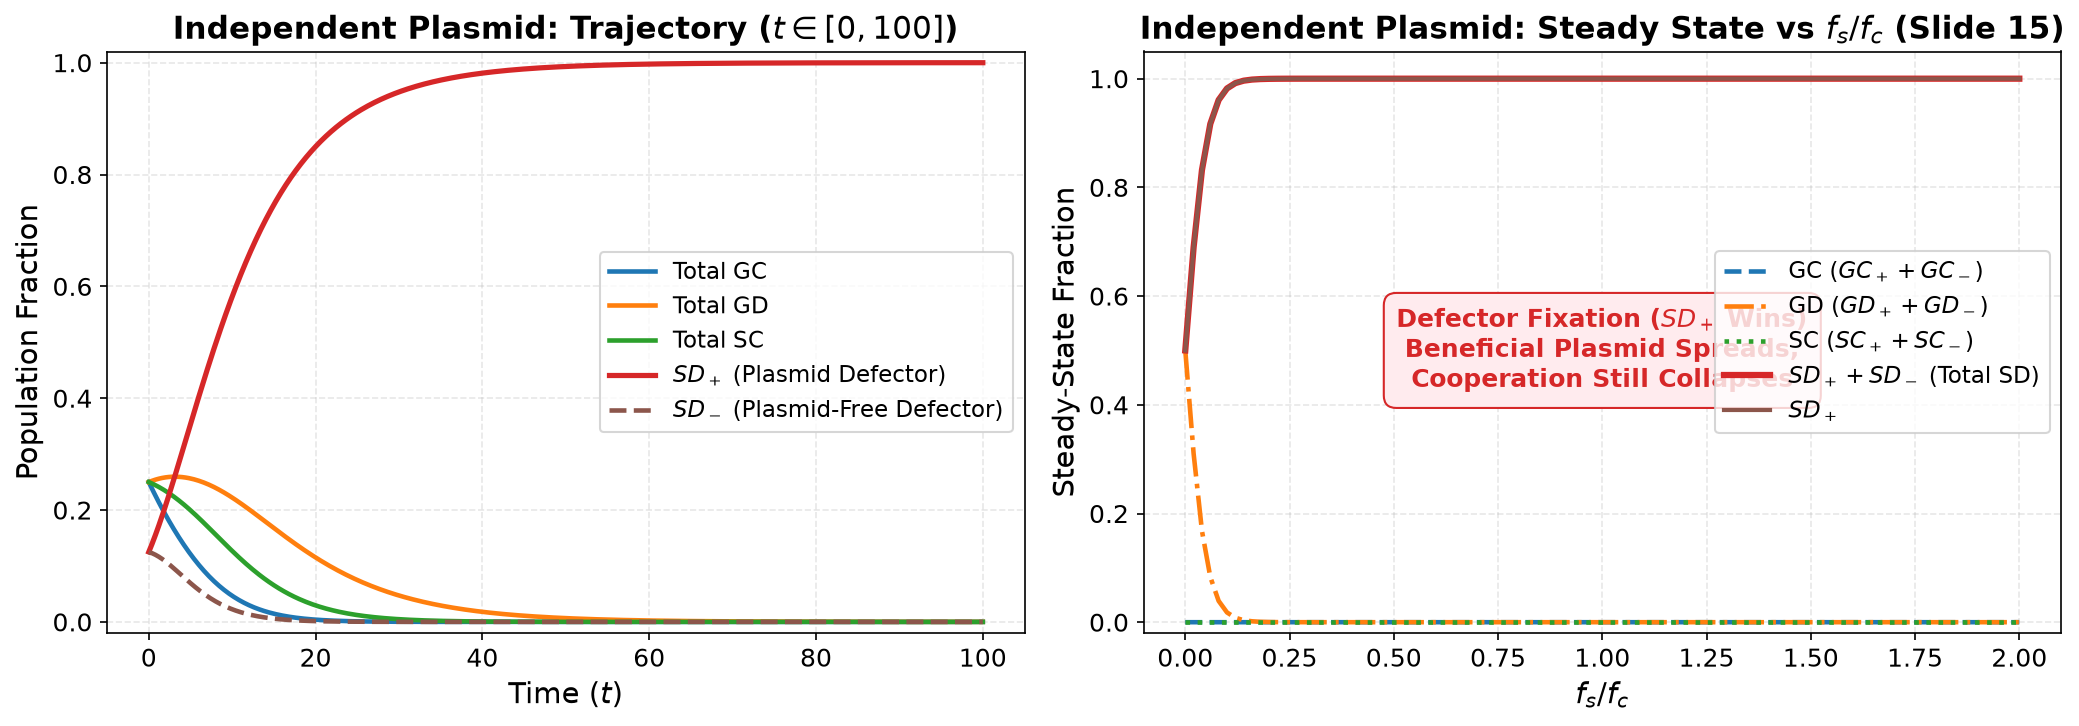

In [3]:
def independent_plasmid_ode(t, y, alpha, fc, fs, fplus):
    GC_p, GC_m, GD_p, GD_m, SC_p, SC_m, SD_p, SD_m = y
    
    f_GC_p = 1.0 - fc + fplus
    f_GC_m = 1.0 - fc
    f_GD_p = 1.0 + fplus
    f_GD_m = 1.0
    f_SC_p = 1.0 + fs - fc + fplus
    f_SC_m = 1.0 + fs - fc
    f_SD_p = 1.0 + fs + fplus
    f_SD_m = 1.0 + fs
    
    f_bar = (1.0 - fc * (GC_p + GC_m + SC_p + SC_m)
             + fs * (SC_p + SC_m + SD_p + SD_m)
             + fplus * (GC_p + GD_p + SC_p + SD_p))
    
    # Differential equations (Slide 14)
    dGC_p = (f_GC_p - f_bar) * GC_p + alpha * (GC_p*GC_m + GC_p*GD_p + GC_p*GD_m + 2.0*GC_m*GD_p)
    dGC_m = (f_GC_m - f_bar) * GC_m + alpha * (GC_m*GD_m - GC_p*GC_m - GC_m*GD_p)
    dGD_p = (f_GD_p - f_bar) * GD_p + alpha * (GD_p*GD_m - GC_p*GD_p - GC_m*GD_p)
    dGD_m = (f_GD_m - f_bar) * GD_m + alpha * (-GC_p*GD_m - GC_m*GD_m - GD_p*GD_m)
    dSC_p = (f_SC_p - f_bar) * SC_p + alpha * (GC_p*SC_m + GC_p*SD_p + GC_p*SD_m + GC_m*SD_p + GD_p*SC_m)
    dSC_m = (f_SC_m - f_bar) * SC_m + alpha * (GC_m*SD_m - GC_p*SC_m - GD_p*SC_m)
    dSD_p = (f_SD_p - f_bar) * SD_p + alpha * (GD_p*SD_m - GC_p*SD_p - GC_m*SD_p)
    dSD_m = (f_SD_m - f_bar) * SD_m + alpha * (-GD_p*SD_m - GC_p*SD_m - GC_m*SD_m)
    
    return [dGC_p, dGC_m, dGD_p, dGD_m, dSC_p, dSC_m, dSD_p, dSD_m]

# 1. Simulate time series
y0_indep = [1/8.0] * 8
fplus = 0.3
sol_indep = spi.solve_ivp(independent_plasmid_ode, t_span, y0_indep, args=(alpha, fc, fs, fplus), t_eval=t_eval, method='RK45')

# 2. Parameter sweep vs fs / fc (Slide 15)
indep_sweep = []
for r in ratios:
    sol = spi.solve_ivp(independent_plasmid_ode, (0, 200), y0_indep, args=(alpha, fc, r * fc, fplus), method='RK45')
    final = np.maximum(0, sol.y[:, -1])
    indep_sweep.append(final / np.sum(final))
indep_sweep = np.array(indep_sweep)

# Plotting Independent Plasmid Model
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Trajectory
ax1.plot(sol_indep.t, sol_indep.y[0] + sol_indep.y[1], label="Total GC", color=COLOR_GC)
ax1.plot(sol_indep.t, sol_indep.y[2] + sol_indep.y[3], label="Total GD", color=COLOR_GD)
ax1.plot(sol_indep.t, sol_indep.y[4] + sol_indep.y[5], label="Total SC", color=COLOR_SC)
ax1.plot(sol_indep.t, sol_indep.y[6], label="$SD_+$ (Plasmid Defector)", color=COLOR_SD, linewidth=2.5)
ax1.plot(sol_indep.t, sol_indep.y[7], label="$SD_-$ (Plasmid-Free Defector)", color=COLOR_SD_PLUS, linestyle="--")
ax1.set_title("Independent Plasmid: Trajectory ($t \in [0, 100]$)", fontweight="bold")
ax1.set_xlabel("Time ($t$)")
ax1.set_ylabel("Population Fraction")
ax1.set_ylim(-0.02, 1.02)
ax1.legend()

# Bifurcation (Slide 15)
total_sd = indep_sweep[:, 6] + indep_sweep[:, 7]
total_gc = indep_sweep[:, 0] + indep_sweep[:, 1]
total_gd = indep_sweep[:, 2] + indep_sweep[:, 3]
total_sc = indep_sweep[:, 4] + indep_sweep[:, 5]

ax2.plot(ratios, total_gc, label="GC ($GC_+ + GC_-$)", color=COLOR_GC, linestyle="--")
ax2.plot(ratios, total_gd, label="GD ($GD_+ + GD_-$)", color=COLOR_GD, linestyle="-.")
ax2.plot(ratios, total_sc, label="SC ($SC_+ + SC_-$)", color=COLOR_SC, linestyle=":")
ax2.plot(ratios, total_sd, label=r"$SD_+ + SD_-$ (Total SD)", color=COLOR_SD, linewidth=3)
ax2.plot(ratios, indep_sweep[:, 6], label=r"$SD_+$", color=COLOR_SD_PLUS, linestyle="-", linewidth=2)
ax2.set_title("Independent Plasmid: Steady State vs $f_s / f_c$ (Slide 15)", fontweight="bold")
ax2.set_xlabel(r"$f_s / f_c$")
ax2.set_ylabel("Steady-State Fraction")
ax2.set_ylim(-0.02, 1.05)
ax2.text(1.0, 0.5, "Defector Fixation ($SD_+$ Wins)\nBeneficial Plasmid Spreads,\nCooperation Still Collapses",
         ha="center", va="center", color=COLOR_SD, fontweight="bold",
         bbox=dict(boxstyle="round,pad=0.5", facecolor="#ffebee", edgecolor=COLOR_SD))
ax2.legend(loc="center right")

plt.tight_layout()
plt.show()


### Inferences from Independent Beneficial Plasmid Model
- **Universal Benefit Flaw:** Because $f_+$ provides equal fitness value to all hosts regardless of cooperation or HGT, the relative fitness differences between types are completely unchanged:
  $$f_{SD_+} - f_{SC_+} = f_c, \quad f_{SD_+} - f_{GD_+} = f_s$$
- **Plasmid Hijacking:** Defectors readily acquire the beneficial plasmid via conjugation ($SD_- + GD_+ \to SD_+ + GD_+$), achieving maximal fitness $f_{SD_+} = 1 + f_s + f_+$.
- **Conclusion:** An independent beneficial plasmid acts as an evolutionary parasite of the social system: it invades the population without rescuing either cooperation or HGT.


---
## 3. Model 3: Dependent Beneficial Plasmid Model (Slides 16–20)

### 3.1 Six Population Types & Conditional Fitness
To link plasmid propagation to sociality, we assume that the plasmid confers a fitness benefit **only when expressed in cooperative hosts** (e.g., public goods machinery enhances plasmid retention, or plasmid carries an enzyme that complements cooperative metabolism).
Defectors do not maintain or benefit from the plasmid, reducing the state space to 6 types:
$$x = [GC_+, GC_-, GD, SC_+, SC_-, SD]^	op$$

### 3.2 Fitness & Mean Fitness
$$\begin{aligned}
f_{GC_+} &= 1 - f_c + f_+ \\
f_{GC_-} &= 1 - f_c \\
f_{GD}   &= 1 \\
f_{SC_+} &= 1 + f_s - f_c + f_+ \\
f_{SC_-} &= 1 + f_s - f_c \\
f_{SD}   &= 1 + f_s
\end{aligned}$$

Mean fitness:
$$\bar{f} = 1 - f_c(GC_+ + GC_- + SC_+ + SC_-) + f_s(SC_+ + SC_- + SD) + f_+(GC_+ + SC_+)$$

### 3.3 Critical Bifurcation Threshold
Notice the fitness competition between the fittest cooperator ($SC_+$) and the fittest defector ($SD$):
$$f_{SC_+} - f_{SD} = (1 + f_s - f_c + f_+) - (1 + f_s) = f_+ - f_c$$
- **Subcritical Regime ($f_+ < f_c \iff f_+ / f_c < 1$):** Defectors have higher fitness; $SD$ dominates.
- **Supercritical Regime ($f_+ > f_c \iff f_+ / f_c > 1$):** Cooperators with plasmid ($SC_+$) outcompete defectors!


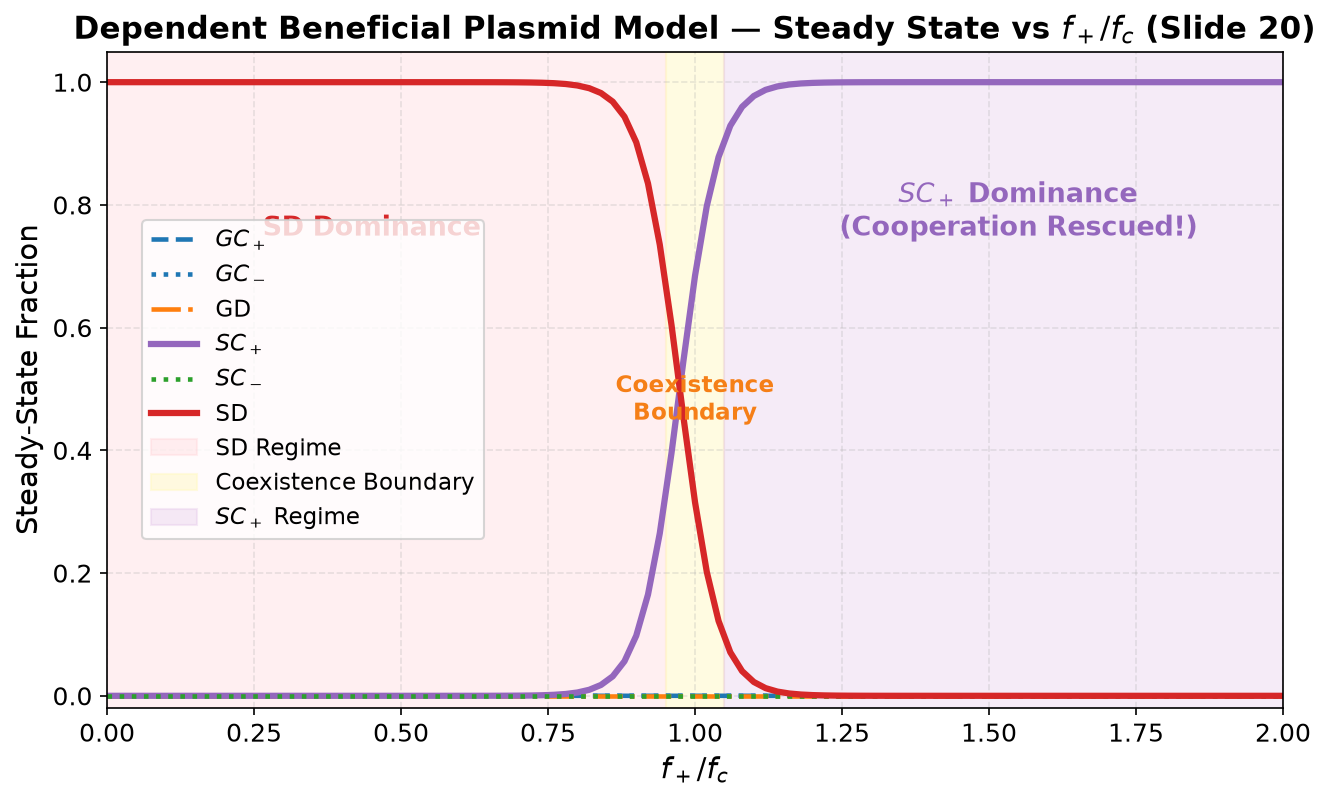

In [4]:
def dependent_plasmid_ode(t, y, alpha, fc, fs, fplus):
    GC_p, GC_m, GD, SC_p, SC_m, SD = y
    
    f_GC_p = 1.0 - fc + fplus
    f_GC_m = 1.0 - fc
    f_GD   = 1.0
    f_SC_p = 1.0 + fs - fc + fplus
    f_SC_m = 1.0 + fs - fc
    f_SD   = 1.0 + fs
    
    f_bar = (1.0 - fc * (GC_p + GC_m + SC_p + SC_m)
             + fs * (SC_p + SC_m + SD)
             + fplus * (GC_p + SC_p))
    
    dGC_p = (f_GC_p - f_bar) * GC_p + alpha * (GC_p * GD + GC_p * GC_m)
    dGC_m = (f_GC_m - f_bar) * GC_m + alpha * (GC_m * GD + GC_m * SD - GC_p * GC_m)
    dGD   = (f_GD   - f_bar) * GD   - alpha * (GC_p * GD + GC_m * GD)
    dSC_p = (f_SC_p - f_bar) * SC_p + alpha * (GC_p * SD + SC_m * GC_p)
    dSC_m = (f_SC_m - f_bar) * SC_m - alpha * (SC_m * GC_p)
    dSD   = (f_SD   - f_bar) * SD   - alpha * (GC_p * SD + GC_m * SD)
    
    return [dGC_p, dGC_m, dGD, dSC_p, dSC_m, dSD]

# 1. Parameter sweep vs f+ / fc (Slide 20)
ratios_fplus = np.linspace(0.0, 2.0, 101)
y0_dep = [1/6.0] * 6
dep_sweep = []
for r in ratios_fplus:
    sol = spi.solve_ivp(dependent_plasmid_ode, (0, 150), y0_dep, args=(alpha, fc, fs, r * fc), method='RK45')
    final = np.maximum(0, sol.y[:, -1])
    dep_sweep.append(final / np.sum(final))
dep_sweep = np.array(dep_sweep)

# Plotting Dependent Plasmid Model
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(ratios_fplus, dep_sweep[:, 0], label="$GC_+$", color=COLOR_GC, linestyle="--")
ax.plot(ratios_fplus, dep_sweep[:, 1], label="$GC_-$", color=COLOR_GC, linestyle=":")
ax.plot(ratios_fplus, dep_sweep[:, 2], label="GD", color=COLOR_GD, linestyle="-.")
ax.plot(ratios_fplus, dep_sweep[:, 3], label="$SC_+$", color=COLOR_SC_PLUS, linewidth=3)
ax.plot(ratios_fplus, dep_sweep[:, 4], label="$SC_-$", color=COLOR_SC, linestyle=":")
ax.plot(ratios_fplus, dep_sweep[:, 5], label="SD", color=COLOR_SD, linewidth=3)

# Slide 20 Shaded Regions
ax.axvspan(0.0, 0.95, color="#ffcdd2", alpha=0.3, label="SD Regime")
ax.axvspan(0.95, 1.05, color="#fff9c4", alpha=0.5, label="Coexistence Boundary")
ax.axvspan(1.05, 2.0, color="#e1bee7", alpha=0.3, label="$SC_+$ Regime")

ax.set_title("Dependent Beneficial Plasmid Model — Steady State vs $f_+ / f_c$ (Slide 20)", fontweight="bold")
ax.set_xlabel(r"$f_+ / f_c$")
ax.set_ylabel("Steady-State Fraction")
ax.set_xlim(0.0, 2.0)
ax.set_ylim(-0.02, 1.05)
ax.text(0.45, 0.75, "SD Dominance", fontsize=13, fontweight="bold", color=COLOR_SD, ha="center")
ax.text(1.0, 0.45, "Coexistence\nBoundary", fontsize=11, fontweight="bold", color="#f57f17", ha="center")
ax.text(1.55, 0.75, "$SC_+$ Dominance\n(Cooperation Rescued!)", fontsize=13, fontweight="bold", color=COLOR_SC_PLUS, ha="center")
ax.legend(loc="center left", bbox_to_anchor=(0.02, 0.5))

plt.tight_layout()
plt.show()


### Inferences from Dependent Beneficial Plasmid Model
- **Cooperation Rescued:** When plasmid benefit depends on cooperation and exceeds cooperation cost ($f_+ > f_c$), cooperative bacteria ($SC_+$) outcompete defectors and fixate in the population!
- **HGT Remains Extinct:** Even though cooperation is saved, generous types ($GC$) are still eliminated because $SC_+$ avoids the cost of conjugation ($f_s$). $GC_+$ pays $f_s$ while $SC_+$ avoids it, so $SC_+$ outgrows $GC_+$.
- **Evolutionary Dilemma:** A dependent plasmid rescues cooperation, but fails to explain the evolution and maintenance of horizontal gene transfer.


---
## 4. Model 4: Plasmid–Chromosome Synergy Model (Slides 21–24)

### 4.1 Positive Epistasis Between Chromosome & Plasmid
In nature, chromosomal genes encoding HGT machinery often exhibit **positive epistasis (synergy)** with plasmid genes (San Millan et al., 2014, *ISME Journal*). For instance, chromosomal relaxases and plasmid partition systems co-optimize cellular metabolism.

In this model:
- The synergistic gain $f_{pc}$ is conferred **specifically to Generous Cooperators ($GC$)**, which carry both chromosomal HGT genes and the cooperative plasmid.
- Population reverts to four core strategies: $x = [GC, GD, SC, SD]^	op$.

### 4.2 Fitness & Mean Fitness
$$\begin{aligned}
f_{GC} &= 1 - f_c + f_{pc} \\
f_{GD} &= 1 \\
f_{SC} &= 1 + f_s - f_c \\
f_{SD} &= 1 + f_s
\end{aligned}$$

Mean fitness:
$$\bar{f} = 1 - f_c(GC + SC) + f_s(SC + SD) + f_{pc}GC$$

### 4.3 Replicator Dynamics & Inherent Threshold
$$\begin{aligned}
\dot{GC} &= (f_{GC} - \bar{f})GC + \alpha \cdot GC \cdot GD \\
\dot{GD} &= (f_{GD} - \bar{f})GD - \alpha \cdot GC \cdot GD \\
\dot{SC} &= (f_{SC} - \bar{f})SC + \alpha \cdot GC \cdot SD \\
\dot{SD} &= (f_{SD} - \bar{f})SD - \alpha \cdot GC \cdot SD
\end{aligned}$$

Comparing $GC$ directly with $SD$:
$$f_{GC} - f_{SD} = (1 - f_c + f_{pc}) - (1 + f_s) = f_{pc} - (f_s + f_c)$$

The critical ratio is:
$$\Gamma = \frac{f_{pc}}{f_s + f_c}$$
- **Low Synergy ($\\Gamma < 0.7$):** Defectors dominate ($SD = 1.0$).
- **Intermediate Synergy ($0.7 \le \\Gamma \le 1.1$):** Coexistence regime! Both $GC$ and $SD$ persist simultaneously.
- **High Synergy ($\\Gamma > 1.1$):** Generous cooperators dominate ($GC = 1.0$). **Both HGT and Cooperation win!**


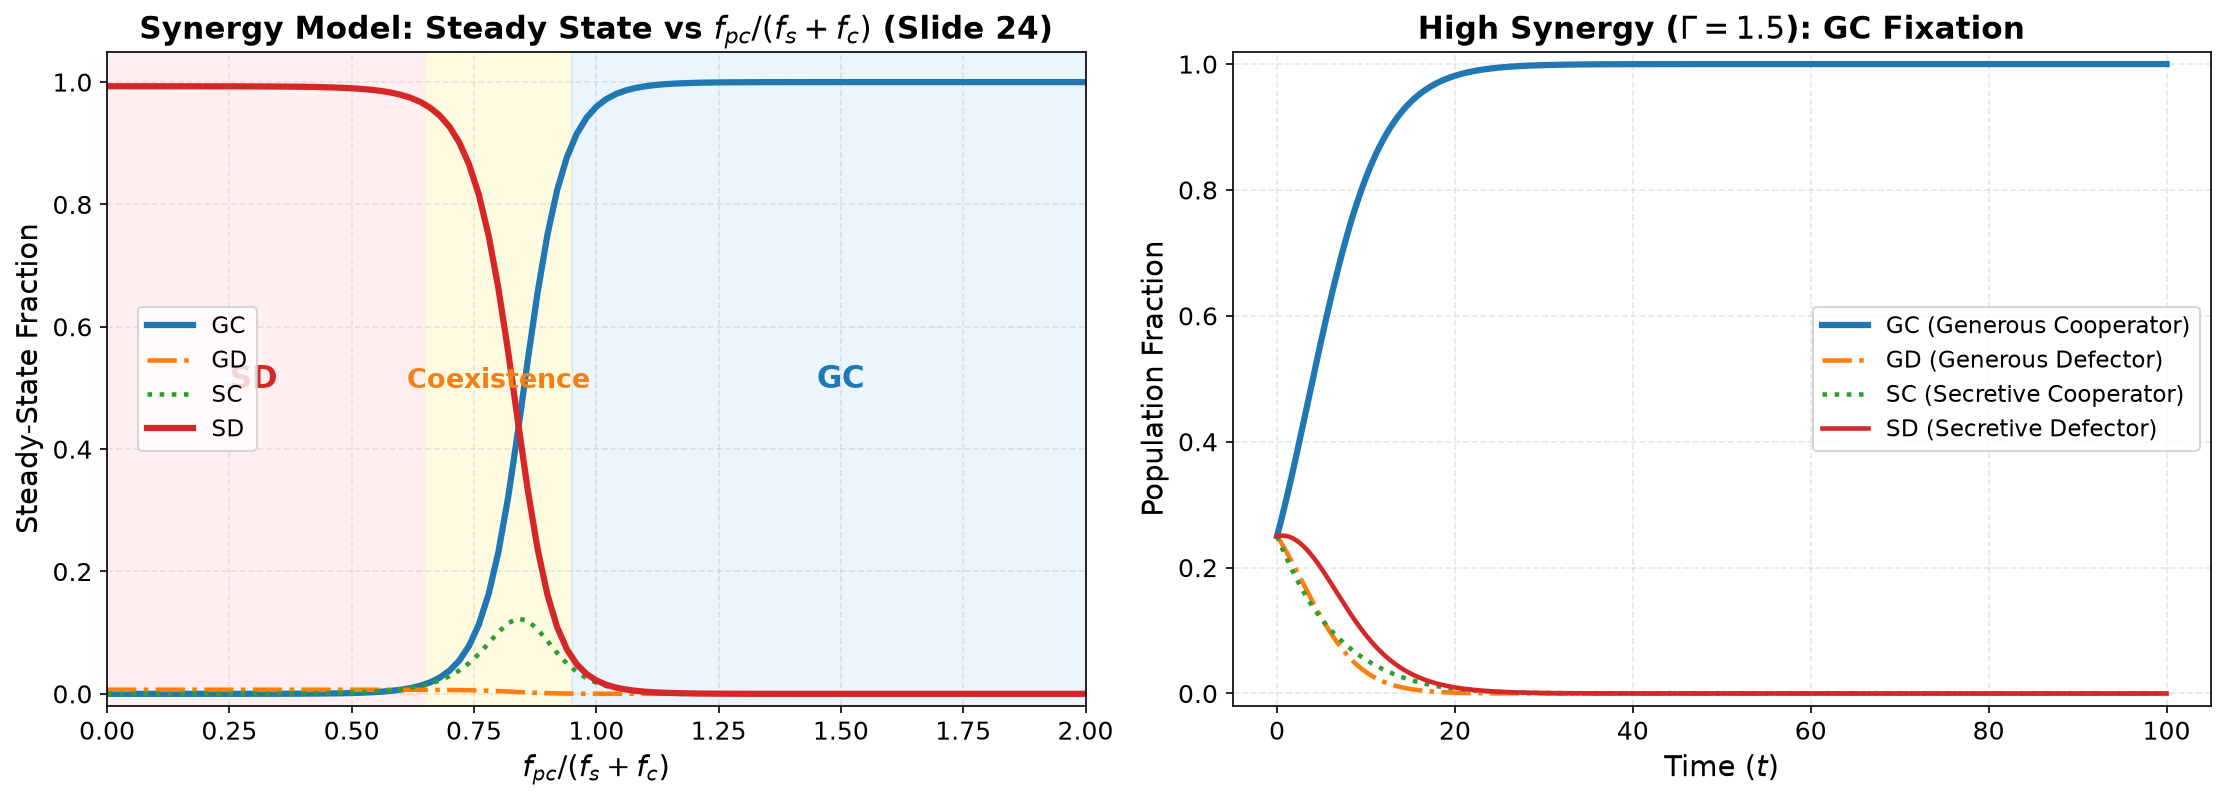

In [5]:
def synergy_model_ode(t, y, alpha, fc, fs, fpc):
    GC, GD, SC, SD = y
    f_GC = 1.0 - fc + fpc
    f_GD = 1.0
    f_SC = 1.0 + fs - fc
    f_SD = 1.0 + fs
    
    f_bar = 1.0 - fc * (GC + SC) + fs * (SC + SD) + fpc * GC
    
    dGC = (f_GC - f_bar) * GC + alpha * GC * GD
    dGD = (f_GD - f_bar) * GD - alpha * GC * GD
    dSC = (f_SC - f_bar) * SC + alpha * GC * SD
    dSD = (f_SD - f_bar) * SD - alpha * GC * SD
    return [dGC, dGD, dSC, dSD]

# 1. Parameter sweep vs f_pc / (f_s + f_c) (Slide 24)
ratios_fpc = np.linspace(0.0, 2.0, 101)
y0_synergy = [0.25, 0.25, 0.25, 0.25]
synergy_sweep = []
# Finite horizon T=50 captures the observable coexistence regime and critical slowing down (Slide 24)
for r in ratios_fpc:
    fpc = r * (fs + fc)
    sol = spi.solve_ivp(synergy_model_ode, (0, 50), y0_synergy, args=(alpha, fc, fs, fpc), method='RK45')
    final = np.maximum(0, sol.y[:, -1])
    synergy_sweep.append(final / np.sum(final))
synergy_sweep = np.array(synergy_sweep)

# 2. Time series for High Synergy vs Low Synergy
t_eval_syn = np.linspace(0, 100, 500)
sol_syn_low = spi.solve_ivp(synergy_model_ode, (0, 100), y0_synergy, args=(alpha, fc, fs, 0.5*(fs+fc)), t_eval=t_eval_syn, method='RK45')
sol_syn_high = spi.solve_ivp(synergy_model_ode, (0, 100), y0_synergy, args=(alpha, fc, fs, 1.5*(fs+fc)), t_eval=t_eval_syn, method='RK45')

# Plotting Synergy Model
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Bifurcation (Slide 24)
ax1.plot(ratios_fpc, synergy_sweep[:, 0], label="GC", color=COLOR_GC, linewidth=3)
ax1.plot(ratios_fpc, synergy_sweep[:, 1], label="GD", color=COLOR_GD, linestyle="-.")
ax1.plot(ratios_fpc, synergy_sweep[:, 2], label="SC", color=COLOR_SC, linestyle=":")
ax1.plot(ratios_fpc, synergy_sweep[:, 3], label="SD", color=COLOR_SD, linewidth=3)

ax1.axvspan(0.0, 0.65, color="#ffcdd2", alpha=0.3)
ax1.axvspan(0.65, 0.95, color="#fff9c4", alpha=0.5)
ax1.axvspan(0.95, 2.0, color="#bbdefb", alpha=0.3)

ax1.set_title("Synergy Model: Steady State vs $f_{pc} / (f_s + f_c)$ (Slide 24)", fontweight="bold")
ax1.set_xlabel(r"$f_{pc} / (f_s + f_c)$")
ax1.set_ylabel("Steady-State Fraction")
ax1.set_xlim(0.0, 2.0)
ax1.set_ylim(-0.02, 1.05)
ax1.text(0.3, 0.5, "SD", fontsize=15, fontweight="bold", color=COLOR_SD, ha="center")
ax1.text(0.8, 0.5, "Coexistence", fontsize=13, fontweight="bold", color="#f57f17", ha="center")
ax1.text(1.5, 0.5, "GC", fontsize=15, fontweight="bold", color=COLOR_GC, ha="center")
ax1.legend(loc="center left", bbox_to_anchor=(0.02, 0.5))

# Trajectory for High Synergy (GC Takeover)
ax2.plot(sol_syn_high.t, sol_syn_high.y[0], label="GC (Generous Cooperator)", color=COLOR_GC, linewidth=3)
ax2.plot(sol_syn_high.t, sol_syn_high.y[1], label="GD (Generous Defector)", color=COLOR_GD, linestyle="-.")
ax2.plot(sol_syn_high.t, sol_syn_high.y[2], label="SC (Secretive Cooperator)", color=COLOR_SC, linestyle=":")
ax2.plot(sol_syn_high.t, sol_syn_high.y[3], label="SD (Secretive Defector)", color=COLOR_SD)
ax2.set_title("High Synergy ($\\Gamma=1.5$): GC Fixation", fontweight="bold")
ax2.set_xlabel("Time ($t$)")
ax2.set_ylabel("Population Fraction")
ax2.set_ylim(-0.02, 1.02)
ax2.legend()

plt.tight_layout()
plt.show()


### Inferences from Plasmid-Chromosome Synergy Model
- **Synergy Bridges the Fitness Gap:** By providing $f_{pc}$ directly to cells carrying both HGT machinery and the cooperative plasmid, $GC$ overcomes both costs simultaneously.
- **Conjugation Accelerates the Takeover:** Once $GC$ gains a fitness advantage, its conjugation actively converts defectors ($GD \to GC$), creating an epidemic-like positive feedback loop that drives $GC$ to 100% fixation.
- **Resolution of the Paradox:** Plasmid-chromosome synergy provides a robust, biologically grounded mechanism explaining how costly horizontal gene transfer and costly cooperation can co-evolve in bacterial populations!


---
## 5. Master Comparative Synthesis (All 4 Models)

The master figure below compiles the steady-state outcomes of all four evolutionary models:


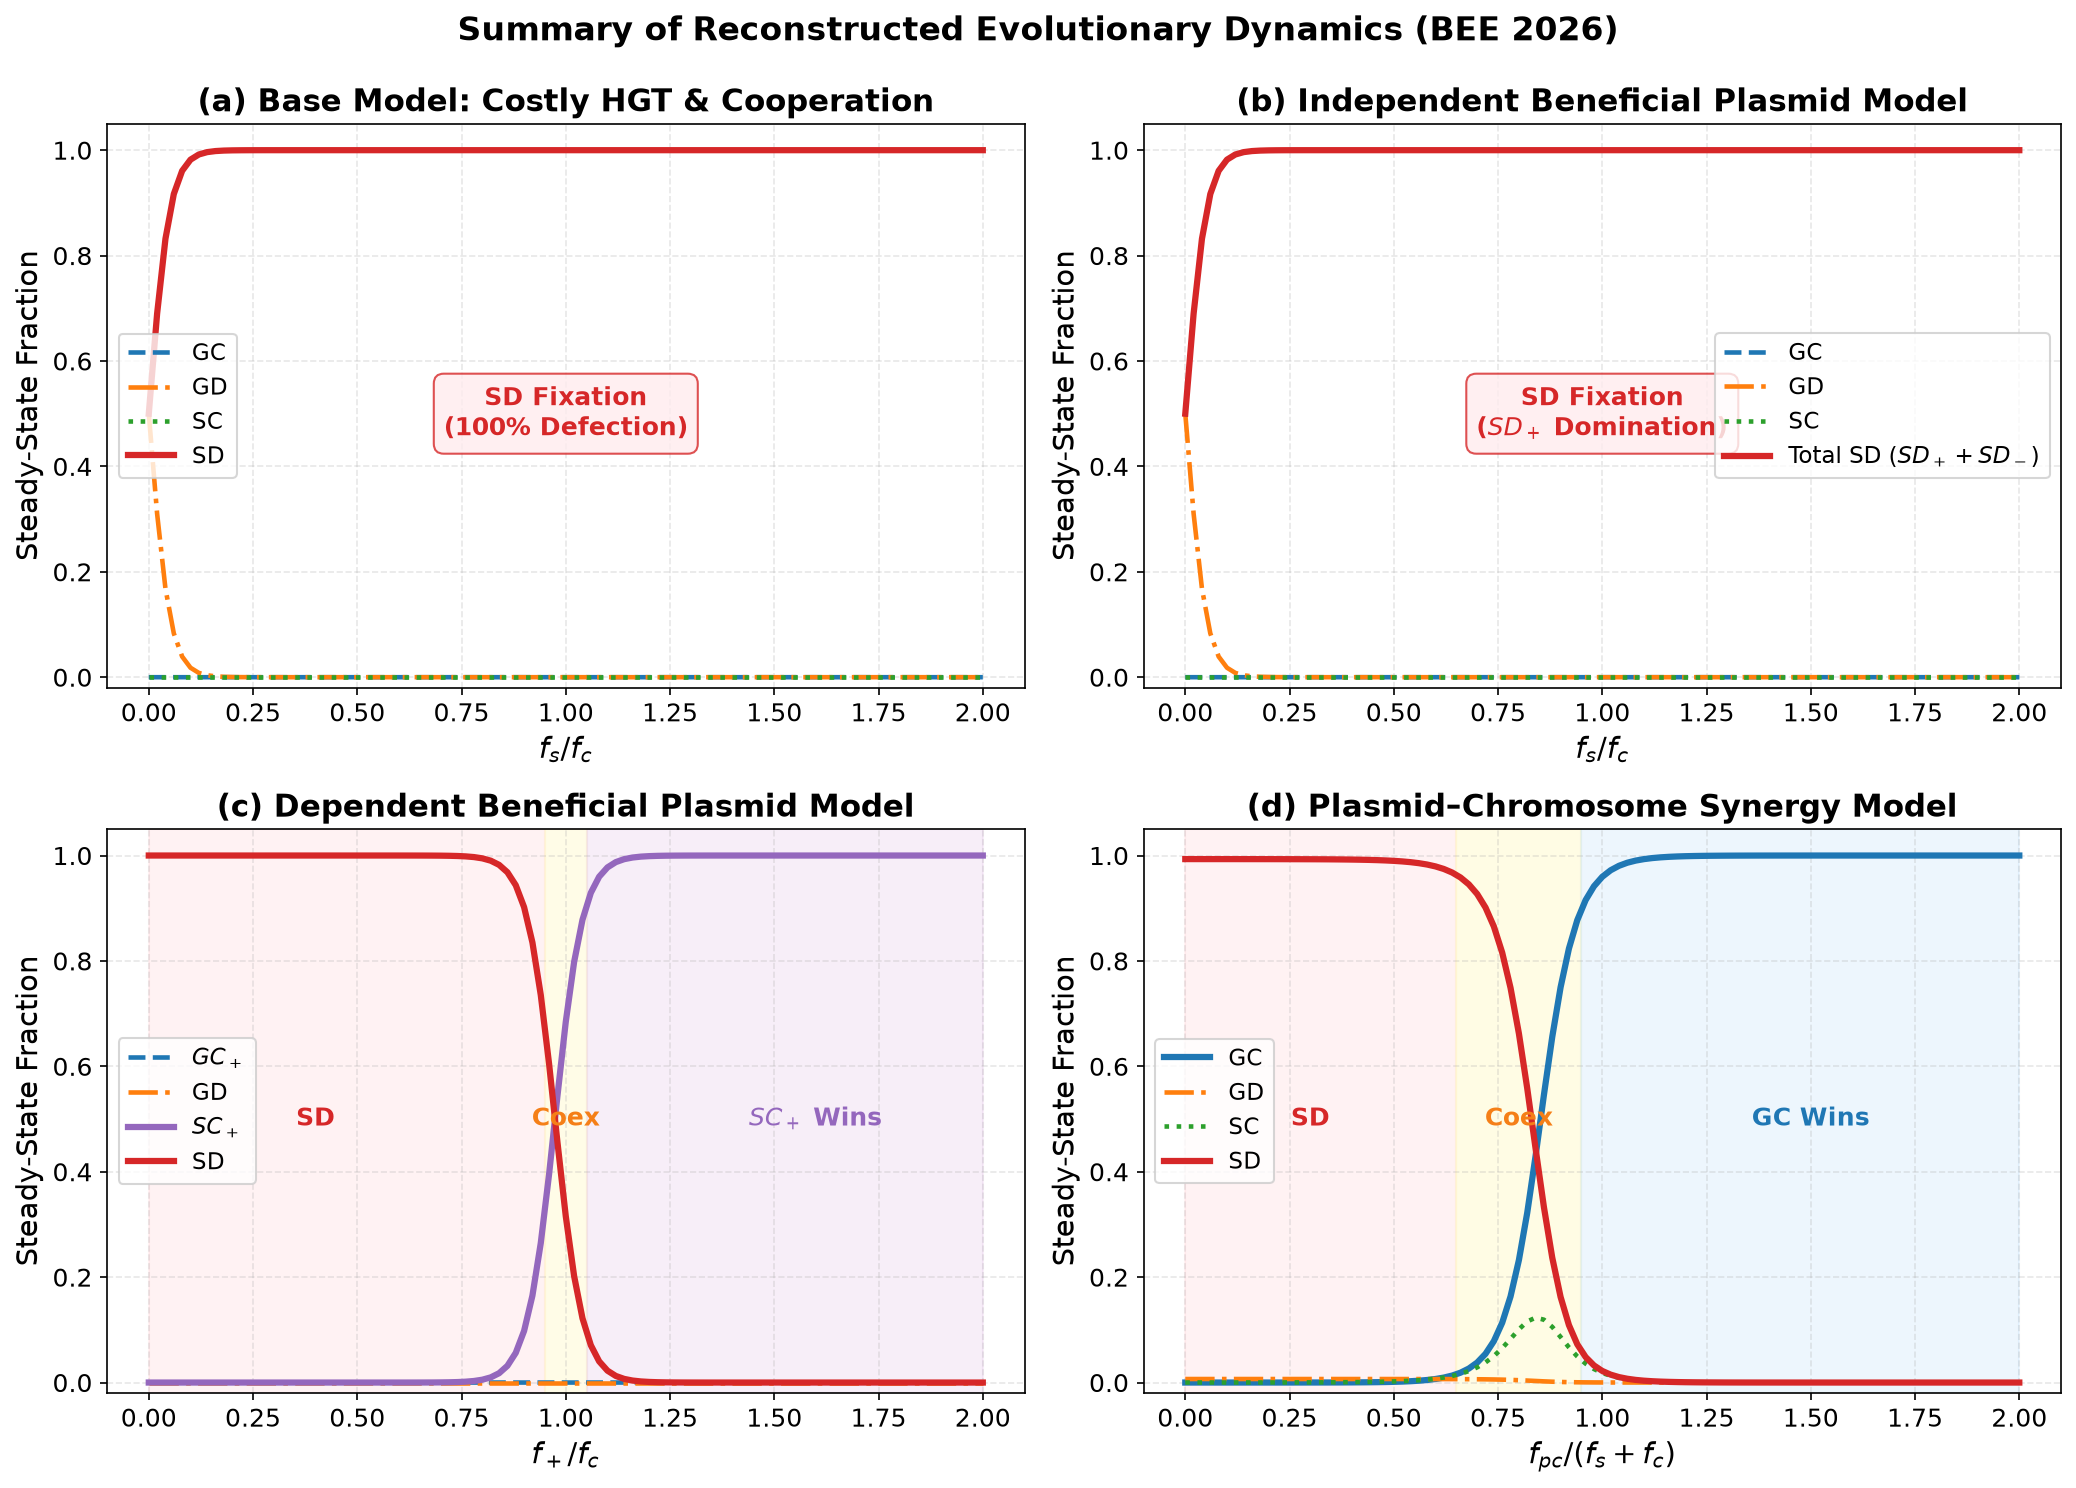

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Base Model
ax = axes[0, 0]
ax.plot(ratios, base_sweep[:, 0], label="GC", color=COLOR_GC, linestyle="--")
ax.plot(ratios, base_sweep[:, 1], label="GD", color=COLOR_GD, linestyle="-.")
ax.plot(ratios, base_sweep[:, 2], label="SC", color=COLOR_SC, linestyle=":")
ax.plot(ratios, base_sweep[:, 3], label="SD", color=COLOR_SD, linewidth=3)
ax.set_title("(a) Base Model: Costly HGT & Cooperation", fontweight="bold")
ax.set_xlabel(r"$f_s / f_c$")
ax.set_ylabel("Steady-State Fraction")
ax.set_ylim(-0.02, 1.05)
ax.text(1.0, 0.5, "SD Fixation\n(100% Defection)", ha="center", va="center", color=COLOR_SD, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.4", facecolor="#ffebee", edgecolor=COLOR_SD, alpha=0.8))
ax.legend(loc="center left")

# 2. Independent Beneficial Plasmid
ax = axes[0, 1]
ax.plot(ratios, total_gc, label="GC", color=COLOR_GC, linestyle="--")
ax.plot(ratios, total_gd, label="GD", color=COLOR_GD, linestyle="-.")
ax.plot(ratios, total_sc, label="SC", color=COLOR_SC, linestyle=":")
ax.plot(ratios, total_sd, label=r"Total SD ($SD_+ + SD_-$)", color=COLOR_SD, linewidth=3)
ax.set_title("(b) Independent Beneficial Plasmid Model", fontweight="bold")
ax.set_xlabel(r"$f_s / f_c$")
ax.set_ylabel("Steady-State Fraction")
ax.set_ylim(-0.02, 1.05)
ax.text(1.0, 0.5, "SD Fixation\n($SD_+$ Domination)", ha="center", va="center", color=COLOR_SD, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.4", facecolor="#ffebee", edgecolor=COLOR_SD, alpha=0.8))
ax.legend(loc="center right")

# 3. Dependent Beneficial Plasmid
ax = axes[1, 0]
ax.plot(ratios_fplus, dep_sweep[:, 0], label="$GC_+$", color=COLOR_GC, linestyle="--")
ax.plot(ratios_fplus, dep_sweep[:, 2], label="GD", color=COLOR_GD, linestyle="-.")
ax.plot(ratios_fplus, dep_sweep[:, 3], label="$SC_+$", color=COLOR_SC_PLUS, linewidth=3)
ax.plot(ratios_fplus, dep_sweep[:, 5], label="SD", color=COLOR_SD, linewidth=3)
ax.axvspan(0.0, 0.95, color="#ffcdd2", alpha=0.25)
ax.axvspan(0.95, 1.05, color="#fff9c4", alpha=0.4)
ax.axvspan(1.05, 2.0, color="#e1bee7", alpha=0.25)
ax.set_title("(c) Dependent Beneficial Plasmid Model", fontweight="bold")
ax.set_xlabel(r"$f_+ / f_c$")
ax.set_ylabel("Steady-State Fraction")
ax.set_ylim(-0.02, 1.05)
ax.text(0.4, 0.5, "SD", ha="center", va="center", color=COLOR_SD, fontweight="bold")
ax.text(1.0, 0.5, "Coex", ha="center", va="center", color="#f57f17", fontweight="bold")
ax.text(1.6, 0.5, "$SC_+$ Wins", ha="center", va="center", color=COLOR_SC_PLUS, fontweight="bold")
ax.legend(loc="center left")

# 4. Synergy Model
ax = axes[1, 1]
ax.plot(ratios_fpc, synergy_sweep[:, 0], label="GC", color=COLOR_GC, linewidth=3)
ax.plot(ratios_fpc, synergy_sweep[:, 1], label="GD", color=COLOR_GD, linestyle="-.")
ax.plot(ratios_fpc, synergy_sweep[:, 2], label="SC", color=COLOR_SC, linestyle=":")
ax.plot(ratios_fpc, synergy_sweep[:, 3], label="SD", color=COLOR_SD, linewidth=3)
ax.axvspan(0.0, 0.65, color="#ffcdd2", alpha=0.25)
ax.axvspan(0.65, 0.95, color="#fff9c4", alpha=0.45)
ax.axvspan(0.95, 2.0, color="#bbdefb", alpha=0.25)
ax.set_title("(d) Plasmid–Chromosome Synergy Model", fontweight="bold")
ax.set_xlabel(r"$f_{pc} / (f_s + f_c)$")
ax.set_ylabel("Steady-State Fraction")
ax.set_ylim(-0.02, 1.05)
ax.text(0.3, 0.5, "SD", ha="center", va="center", color=COLOR_SD, fontweight="bold")
ax.text(0.8, 0.5, "Coex", ha="center", va="center", color="#f57f17", fontweight="bold")
ax.text(1.5, 0.5, "GC Wins", ha="center", va="center", color=COLOR_GC, fontweight="bold")
ax.legend(loc="center left")

plt.suptitle("Summary of Reconstructed Evolutionary Dynamics (BEE 2026)", fontweight="bold", fontsize=16, y=0.99)
plt.tight_layout()
plt.show()


---
## 6. Future Directions & Research Extensions

1. **Spatial Structure & Viscous Populations:**
   - Real microbial communities inhabit structured biofilms where diffusion is localized.
   - *Extension:* Implement reaction-diffusion PDEs or 2D cellular automata (agent-based lattices) to examine how spatial clustering protects cooperators from cheater exploitation.

2. **Demographic Stochasticity & Genetic Drift:**
   - Deterministic ODEs assume infinite population size ($N \to \infty$). In small colonies or transmission bottlenecks, demographic noise can flip stable states.
   - *Extension:* Formulate continuous-time Markov jump processes (Gillespie algorithm) and calculate fixation probabilities as a function of effective population size $N_e$.

3. **Chemostat Dilution & Resource Dynamics:**
   - Incorporate explicit substrate ($S$) and public goods ($P$) equations:
     $$\frac{dS}{dt} = D(S_0 - S) - \sum_i \mu_i(S) x_i$$
   - Model conjugation as cell-contact dependent on total biomass density rather than constant rate $\alpha$.

4. **Multi-Plasmid Epistasis & CRISPR-Cas Defense:**
   - Microbes carry immune defenses (CRISPR-Cas, restriction-modification systems) that restrict costly plasmids while permitting beneficial ones.
   - *Extension:* Multi-locus genetic models with defense costs and co-evolutionary arms races between plasmid infectivity and host resistance.

---

## 7. Project Credits & Acknowledgements

This study is a reconstruction of the team research project conducted during **Behavior, Evolution, Emergence 2026 (BEE 2026)** at **The Institute of Mathematical Sciences (IMSc), Chennai**:

- **Team Members:**
  - **Ananya** (IMSc BEE 2026)
  - **Shrayansh** (IMSc BEE 2026)
  - **Yogesh** (IMSc BEE 2026)

- **Special Thanks to BEE Instructors & Mentors:**
  - Shakti, Saptarishi, Kalyani, Varuni, Saini

### References
1. Alvaro San Millan, Karl Heilbron, R Craig MacLean. *Positive epistasis between co-infecting plasmids promotes plasmid survival in bacterial populations.* The ISME Journal, 8(3):601–612, 2014. [doi:10.1038/ismej.2013.182](https://doi.org/10.1038/ismej.2013.182)
2. Harrison et al. *Indirect Fitness Benefits Enable the Spread of Host Genes Promoting Costly Transfer of Beneficial Plasmids.* PLOS Biology, 14(12):e1002478, 2016. [doi:10.1371/journal.pbio.1002478](https://doi.org/10.1371/journal.pbio.1002478)
3. Smith et al. *Genetic information transfer promotes cooperation in bacteria.* PNAS, 111(40):14068–14073, 2014. [doi:10.1073/pnas.1406840111](https://doi.org/10.1073/pnas.1406840111)
4. West, S. A., & Gardner, A. *Public goods and cheating in microbes.* Current Biology, 29(11):R445-R449, 2019.
5. Niehus et al. *Bacterial cooperation through horizontal gene transfer.* Trends in Ecology & Evolution, 36(4):309–318, 2021.
